#### 04D · ¿Arregla la gaussianización de las PCs la cola del PVAR?
Diagnóstico de 04C: el PVAR reproduce la varianza de cada PC por mes, pero le falta **curtosis** en las diferencias de presión locales (≈ 0,8 real vs ≈ 0 en el PVAR en primavera y otoño) → q99 del gradiente en transición 0,73–0,86 del histórico.

Prueba (una pieza): mismo PVAR que producción (p = 10, 1 armónico, 6 h) ajustado sobre
- **A**: tus 30 PCs tal cual (referencia),
- **B**: las mismas PCs **gaussianizadas** (armónicos → PIT empírica por mes → normal), simulando en espacio normal y deshaciendo la transformación.

Métricas (las de 04C): q99 del gradiente en el sitio por mes y curtosis de dpx/dpy, calculados del campo de presión reconstruido con tus PCs (regresión B).

In [9]:
import time, glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import kurtosis

from utils.pit.piece_wise_marginal import PiecewiseMarginal, to_normal, from_normal
from utils.pit.empirical_marginal import EmpiricalPiece
from utils.tv_var.harmonic_standardizer import HarmonicStandardizer
from utils.tv_var.periodic_var import PeriodicVAR

In [10]:
#### Configuración
FIELD_PATH = "/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/daily_atmospheric/outputs/data/era5_mslp_grad_1985_2026_1deg_hourly.zarr"
PCS_PATH = "outputs/pca/pcs_msl_sel_6h.csv"                 # tus 30 PCs (las que simula el PVAR)
VAR, LAT, LON, TIME = "msl", "latitude", "longitude", "valid_time"
SITIO = (39.6, 3.4)                                         # cerca de Cala Millor
P_VAR, N_HARM = 10, 1                                       # como producción
N_SIMS_PV, N_ANOS = 5, 40

In [11]:
#### PCs y campo de presión 6-horario 1985–2025
p_mia = pd.read_csv(PCS_PATH, index_col=0, parse_dates=True).loc["1985":"2025"]
ds = xr.open_zarr(FIELD_PATH) if FIELD_PATH.endswith(".zarr") else xr.open_dataset(FIELD_PATH)
ds = ds[VAR].rename({TIME: "time"}).sel(time=slice("1985-01-01", "2025-12-31"))
ds = ds.sel(time=ds.time.dt.hour.isin([0, 6, 12, 18])).transpose("time", LAT, LON)
P = ds.values.astype("float32")
T_, ny, nx = P.shape
tiempo = pd.DatetimeIndex(ds.time.values)
lat_rad = np.deg2rad(np.abs(ds[LAT].values))
p_mia = p_mia.reindex(tiempo)
print(P.shape, "| pasos sin PCs:", int(p_mia.isna().any(axis=1).sum()))
p_mia = p_mia.ffill().bfill()

(59900, 30, 60) | pasos sin PCs: 0


In [12]:
#### Reconstrucción del campo desde tus 30 PCs (regresión B) y gradiente (fórmula de bluemath spatial_gradient)
X = P.reshape(T_, -1)
A = np.c_[np.ones(T_), p_mia.values]
B, *_ = np.linalg.lstsq(A, X, rcond=None)                   # (31, npts)
print(f"varianza del campo explicada por tus 30 PCs: {1 - ((X - A @ B) ** 2).sum() / ((X - X.mean(0)) ** 2).sum():.3f}")
del A

def gradiente(F):
    c = F[:, 1:-1, 1:-1]
    l = np.roll(F, -1, axis=2)[:, 1:-1, 1:-1]; r = np.roll(F, 1, axis=2)[:, 1:-1, 1:-1]
    u = np.roll(F, -1, axis=1)[:, 1:-1, 1:-1]; d = np.roll(F, 1, axis=1)[:, 1:-1, 1:-1]
    cphi = np.cos(lat_rad[1:-1])[None, :, None]
    g = (((c - l) / cphi) ** 2 + ((r - c) / cphi) ** 2) / 2 + ((c - d) ** 2 + (u - c) ** 2) / 2
    return g.reshape(len(F), -1).astype("float32")

iy = np.abs(ds[LAT].values[1:-1] - SITIO[0]).argmin(); ix = np.abs(ds[LON].values[1:-1] - SITIO[1]).argmin()
j_sitio = iy * (nx - 2) + ix

def grad_sitio(pcs_df, paso=4000):
    """PCs → campo reconstruido con B → gradiente al cuadrado en el sitio."""
    V = pcs_df[p_mia.columns].values
    out = []
    for i in range(0, len(V), paso):
        Vi = V[i:i + paso]
        F = (np.c_[np.ones(len(Vi)), Vi] @ B).astype("float32").reshape(-1, ny, nx)
        out.append(gradiente(F)[:, j_sitio])
    return pd.Series(np.concatenate(out), index=pcs_df.index)

#### Diferencias de presión en el sitio (lineales en las PCs)
yy, xx = iy + 1, ix + 1
pts = {"e": (0, 1), "w": (0, -1), "n": (1, 0), "s": (-1, 0)}
Bp = B[:, [(yy + dy) * nx + (xx + dx) for dy, dx in pts.values()]]
cphi_s = np.cos(lat_rad[yy])
def difs(pcs_df):
    V = np.c_[np.ones(len(pcs_df)), pcs_df[p_mia.columns].values] @ Bp
    return pd.DataFrame({"dpx": (V[:, 0] - V[:, 1]) / (2 * cphi_s), "dpy": (V[:, 2] - V[:, 3]) / 2}, index=pcs_df.index)

varianza del campo explicada por tus 30 PCs: 0.959


#### 1. Gaussianización de las PCs: armónicos → PIT empírica por mes → normal

In [13]:
harm_pc = HarmonicStandardizer(n_harmonics=3).fit(p_mia)
s_pc = harm_pc.transform(p_mia)
marg_pc = {(c_, m): PiecewiseMarginal([EmpiricalPiece()], []).fit(s_pc.loc[s_pc.index.month == m, c_])
           for c_ in s_pc.columns for m in range(1, 13)}

def gauss(s):
    out = pd.DataFrame(index=s.index, columns=s.columns, dtype=float)
    for (c_, m), mg in marg_pc.items():
        sel = s.index.month == m
        out.loc[sel, c_] = to_normal(pd.Series(mg.cdf(s.loc[sel, c_].values), index=s.index[sel])).values
    return out

def desgauss(g):
    out = pd.DataFrame(index=g.index, columns=g.columns, dtype=float)
    for (c_, m), mg in marg_pc.items():
        sel = g.index.month == m
        out.loc[sel, c_] = mg.ppf(from_normal(pd.Series(g.loc[sel, c_].values)).values)
    return harm_pc.inverse_transform(out)

g_pc = gauss(s_pc)
print("ida y vuelta (máx. error relativo):", float((desgauss(g_pc) - p_mia).abs().max().max() / p_mia.abs().max().max()))
est_ = lambda ix_: np.where(ix_.month.isin([11, 12, 1, 2]), "invierno", np.where(ix_.month.isin([3, 4, 5, 9, 10]), "transición", "verano"))
k_antes = s_pc.groupby(est_(s_pc.index)).apply(lambda x: pd.Series(kurtosis(x), index=x.columns))
print("curtosis marginal de las PCs antes de gaussianizar (sobre las 30):")
print(pd.DataFrame({"mediana": k_antes.median(axis=1), "máximo": k_antes.max(axis=1), "PC del máximo": k_antes.idxmax(axis=1)}).round(2).to_string())

ida y vuelta (máx. error relativo): 1.2199486801537374e-15
curtosis marginal de las PCs antes de gaussianizar (sobre las 30):
            mediana  máximo PC del máximo
invierno       0.16    0.39      msl_PC20
transición     0.07    0.25      msl_PC41
verano         0.01    0.27      msl_PC12


#### 2. Dos PVAR iguales que producción: A (PCs tal cual) y B (gaussianizadas)

In [14]:
t = time.time()
pv_A = PeriodicVAR(p=P_VAR, n_harm=N_HARM, freq="6h").fit(p_mia)
pv_B = PeriodicVAR(p=P_VAR, n_harm=N_HARM, freq="6h").fit(g_pc)
print(f"ajustes ({time.time() - t:.0f} s)")
sims = {"A": [], "B": []}
for i in range(N_SIMS_PV):
    t = time.time()
    sims["A"].append(pv_A.simulate(n_years=N_ANOS, seed=100 + i))
    sims["B"].append(desgauss(pv_B.simulate(n_years=N_ANOS, seed=100 + i)))
    print(f"sim {i} ({time.time() - t:.0f} s)", flush=True)

/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model/utils/tv_var/periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model/utils/tv_var/periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model

ajustes (12 s)
sim 0 (2 s)
sim 1 (2 s)
sim 2 (2 s)
sim 3 (2 s)
sim 4 (3 s)


#### 3. ¿Mejora la cola en transición? (mismas métricas que 04C)

In [15]:
g_h = grad_sitio(p_mia)
d_hh = difs(p_mia)
q_hist = g_h.groupby(g_h.index.month).quantile(0.99)
res_q, res_k, res_s = {}, {}, {}
for c_ in ["dpx", "dpy"]:
    res_k[(c_, "histórico")] = d_hh[c_].groupby(d_hh.index.month).apply(kurtosis)
for v in ["A", "B"]:
    gs = pd.concat([grad_sitio(s_) for s_ in sims[v]])
    res_q[v] = gs.groupby(gs.index.month).quantile(0.99) / q_hist
    ds_ = pd.concat([difs(s_) for s_ in sims[v]])
    for c_ in ["dpx", "dpy"]:
        res_k[(c_, v)] = ds_[c_].groupby(ds_.index.month).apply(kurtosis)
        res_s[(c_, v)] = ds_[c_].groupby(ds_.index.month).std() / d_hh[c_].groupby(d_hh.index.month).std()
    res_q[v + " (máx. anual, mediana)"] = pd.Series(gs.groupby(gs.index.year).max().median() / g_h.groupby(g_h.index.year).max().median(), index=[0])
print("q99 del gradiente en el sitio, ratio sim/hist por mes:")
display(pd.DataFrame({v: res_q[v] for v in ["A", "B"]}).T.round(2))
print("máx. anual (mediana) sim/hist:  A", round(float(res_q["A (máx. anual, mediana)"].iloc[0]), 2), "| B", round(float(res_q["B (máx. anual, mediana)"].iloc[0]), 2))
print("curtosis de las diferencias de presión locales:")
display(pd.DataFrame(res_k).T.round(2))
print("std sim/hist de dpx/dpy por mes:")
display(pd.DataFrame(res_s).T.round(2))

q99 del gradiente en el sitio, ratio sim/hist por mes:


,1,2,3,4,5,6,7,8,9,10,11,12
A,1.00,1.09,0.82,0.75,0.71,1.07,1.25,1.13,0.76,0.69,0.76,0.91
B,1.01,1.14,0.83,0.77,0.71,0.96,1.14,1.02,0.71,0.73,0.78,0.96


máx. anual (mediana) sim/hist:  A 1.05 | B 1.12
curtosis de las diferencias de presión locales:


,,1,2,3,4,5,6,7,8,9,10,11,12
dpx,histórico,0.37,0.75,0.85,0.89,0.78,0.24,0.05,0.35,0.51,0.81,0.52,0.27
dpy,histórico,0.45,0.21,0.30,0.28,0.78,1.00,0.45,0.86,0.93,0.88,0.19,0.30
dpx,A,0.00,-0.01,-0.03,0.01,-0.09,-0.00,0.05,0.07,0.01,-0.05,0.16,0.03
dpy,A,-0.07,-0.00,0.04,0.03,-0.03,0.01,-0.01,0.06,-0.01,-0.16,-0.07,-0.02
dpx,B,-0.05,-0.01,-0.04,0.02,-0.01,-0.00,0.04,0.11,0.08,-0.00,0.17,0.04
dpy,B,-0.14,0.09,0.04,0.05,0.03,0.04,0.02,0.12,0.02,-0.12,-0.09,-0.02


std sim/hist de dpx/dpy por mes:


,,1,2,3,4,5,6,7,8,9,10,11,12
dpx,A,1.06,1.08,0.96,0.93,0.97,1.12,1.07,1.06,1.13,0.97,0.88,0.99
dpy,A,1.07,1.09,0.94,0.91,0.96,1.07,1.15,1.12,0.97,0.95,0.94,1.00
dpx,B,1.07,1.11,0.99,0.94,0.97,1.07,1.01,0.99,1.09,0.97,0.90,0.99
dpy,B,1.09,1.09,0.94,0.90,0.94,1.01,1.08,1.06,0.94,0.97,0.94,1.02


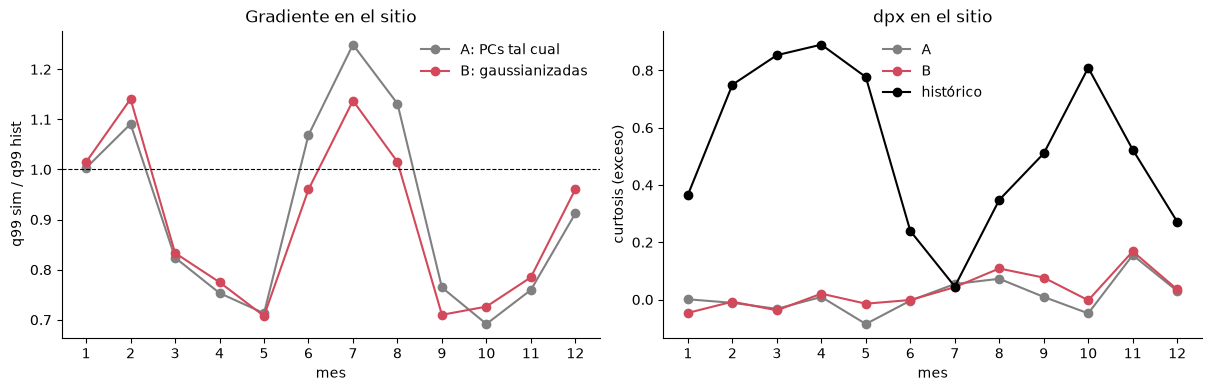

In [16]:
#### Figura: q99 del gradiente por mes (ratio) y curtosis de dpx
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for v, col in [("A", "0.5"), ("B", "#d1495b")]:
    ax[0].plot(res_q[v].index, res_q[v].values, "o-", color=col, label=f"{v}: {'PCs tal cual' if v == 'A' else 'gaussianizadas'}")
    ax[1].plot(res_k[("dpx", v)].index, res_k[("dpx", v)].values, "o-", color=col, label=v)
ax[0].axhline(1, color="k", lw=0.8, ls="--")
ax[1].plot(res_k[("dpx", "histórico")].index, res_k[("dpx", "histórico")].values, "o-", color="k", label="histórico")
ax[0].set(xlabel="mes", ylabel="q99 sim / q99 hist", title="Gradiente en el sitio", xticks=range(1, 13))
ax[1].set(xlabel="mes", ylabel="curtosis (exceso)", title="dpx en el sitio", xticks=range(1, 13))
for a in ax:
    a.spines[["top", "right"]].set_visible(False); a.legend(frameon=False)
plt.show()

#### Cómo leerlo
- **A** repite el diagnóstico de 04C (q99 en transición 0,73–0,86; curtosis ≈ 0). Es la referencia.
- **B sube la curtosis y el q99 en transición hacia el histórico** → la gaussianización ayuda; siguiente paso: B en la cadena completa (08 + 09B).
- **B ≈ A** → la cola no está en la marginal de cada PC (ya casi gaussiana: ver la curtosis marginal de la celda 1) sino en cómo varían juntas → régimen en Σ (MS) es el camino.
- La gaussianización por mes no puede crear valores de cada PC fuera del rango histórico de su mes (la PIT empírica está acotada); aquí no importa porque se mira la curtosis, no el máximo absoluto.